# 3 · Fit your own threshold

Have a list of landslides and the rain that triggered them? `fit_threshold` gives a threshold for your area. Here we use the landslides of one region of e-ITALICA, Liguria, as if they were yours, and compare the result with the national lines.

> **A threshold exceeded is not an alert.** It says the rain is like the rain that triggered landslides before. The official alert in Italy is the criticality bulletin of the Dipartimento della Protezione Civile.

In [1]:
import matplotlib.pyplot as plt

from rainfall_thresholds import ITALICA_T5, fit_threshold

In [2]:
import csv
from pathlib import Path

FIXTURE = Path("../tests/fixtures/italica_v4_dur_rain.csv")
with FIXTURE.open(encoding="utf-8") as f:
    italica = [
        (r["region"], float(r["duration_h"]), float(r["cumulated_rainfall_mm"]))
        for r in csv.DictReader(f)
    ]
len(italica)

5974

In [3]:
liguria = [(d, e / d) for region, d, e in italica if region == "Liguria"]
fit = fit_threshold(liguria, percentile=5)
t = fit.threshold
print(f"Liguria, {fit.n_events} landslides: T5 I = {t.alpha:.2f} D^-{t.beta:.3f}")
for name, other in (
    ("Liguria", t),
    ("northern", ITALICA_T5["northern"]),
    ("italy", ITALICA_T5["italy"]),
):
    print(
        f"{name:>9}: {other.cumulated(24):5.1f} mm in 24 h, {other.cumulated(72):5.1f} mm in 72 h"
    )

Liguria, 1603 landslides: T5 I = 6.76 D^-0.506
  Liguria:  32.5 mm in 24 h,  56.0 mm in 72 h
 northern:  30.0 mm in 24 h,  51.3 mm in 72 h
    italy:  28.3 mm in 24 h,  45.5 mm in 72 h


## The percentile is a choice

A lower percentile catches more landslides and is exceeded more often on ordinary days. How often is not in a landslide catalogue: it needs the rain of the days without landslides ([#7](https://github.com/agent-engineering-studio/rainfall-thresholds/issues/7)).

In [4]:
for p in (1, 5, 10, 20, 50):
    t = fit_threshold(liguria, percentile=p).threshold
    print(f"T{p:<2}: {t.cumulated(24):5.1f} mm in 24 h")

T1 :  20.9 mm in 24 h
T5 :  32.5 mm in 24 h
T10:  43.3 mm in 24 h
T20:  58.6 mm in 24 h
T50: 124.5 mm in 24 h


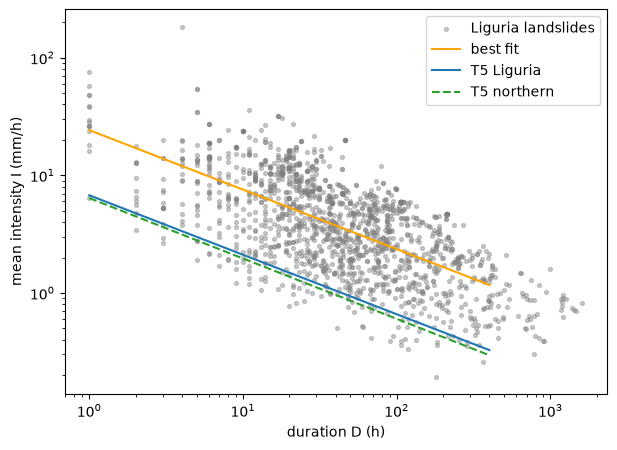

In [5]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(
    [d for d, _ in liguria],
    [i for _, i in liguria],
    s=8,
    alpha=0.4,
    color="grey",
    label="Liguria landslides",
)
xs = [1 + k * 0.5 for k in range(0, 2 * 400)]
ax.plot(xs, [fit.central.intensity(x) for x in xs], color="orange", label="best fit")
ax.plot(xs, [fit.threshold.intensity(x) for x in xs], color="tab:blue", label="T5 Liguria")
ax.plot(
    xs,
    [ITALICA_T5["northern"].intensity(x) for x in xs],
    "--",
    color="tab:green",
    label="T5 northern",
)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("duration D (h)")
ax.set_ylabel("mean intensity I (mm/h)")
ax.legend()
plt.show()

**Good to know.** A threshold fitted on a few dozen landslides moves a lot with the sample: published thresholds use hundreds. The rain of e-ITALICA comes from rain gauges; a threshold fitted on gauges is not validated on radar or model rain.